# Clima de aula y rendimiento en Saber 3°, 5° y 9° (2022): réplica y extensión

Cuaderno limpio del proyecto. Replica la Tabla 4 de la tesis *"Incidencia del Clima de Aula en el Rendimiento Escolar en Colombia"* y la extiende, usando **10 valores plausibles (PV) + 84 réplicas BRR (Fay = 0,5)**. Las funciones de inferencia están en `src/saber_brr.py` (validadas con 21 tests).

**Cómo ejecutarlo:** `Entorno de ejecución > Ejecutar todo`. Necesita `saber_brr.py` en `saber-clima-aula/src/` y la base de DataIcfes. Tarda unos 10 a 15 minutos, casi todo en las regresiones.

| Sección | Contenido |
|---|---|
| 0 | Configuración |
| 1 | Auditoría de datos |
| 2 | Datasets de análisis |
| 3 | Validación de la implementación |
| 4 | Réplica de la Tabla 4 |
| 5 | Extensión: modelo ampliado, robustez y mitigación |
| 6 | Figura y exportación de resultados |

**Lectura de resultados:** todo es asociación (datos transversales y autorreportados), no efecto causal. Los valores "de referencia" de cada sección son los obtenidos en la ejecución original, para que pueda verificar que su corrida coincide.

## 0. Configuración

In [1]:
import os, sys
from pathlib import Path

try:                                   # en Colab se monta Drive; fuera de Colab se omite
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

# Única sección con rutas. Se pueden sobrescribir con variables de entorno.
REPO       = Path(os.environ.get('SABER_REPO', '/content/drive/MyDrive/Colab Notebooks/saber-clima-aula'))
RUTA_DATOS = Path(os.environ.get('SABER_DATA', '/content/drive/MyDrive/Colab Notebooks/datos/Prueba_Saber_3579_2022.txt'))
DIR_SALIDA = REPO / 'reports'
DIR_SALIDA.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(REPO / 'src'))

import numpy as np
import pandas as pd
import saber_brr as sb

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 200)

AREAS = [('Matemáticas', 'matepv'), ('Lectura', 'lectpv')]

Mounted at /content/drive


## 1. Auditoría de datos

Objetivo: saber qué hay en la base y qué variables del modelo de la tesis tienen nulos estructurales.

In [2]:
if RUTA_DATOS.suffix == '.parquet':
    df = pd.read_parquet(RUTA_DATOS)
else:
    df = pd.read_csv(RUTA_DATOS, sep=';', encoding='utf-8', low_memory=False)
df.columns = df.columns.str.lower().str.strip()
print('Filas, columnas:', df.shape)            # referencia: (108074, 196)

Filas, columnas: (108074, 196)


In [3]:
# Estructura frente al diccionario ICFES
esperadas = ['peso', 'grado', 'sexo', 'nse', 'seczon', 'region', 'ubicacion_sede',
             'naturaleza_establecimiento', 'departamento', 'ind_hse', 'ind_fe_3',
             'ind_fe_4', 'ind_fe_5', 'ind_fe_6', 'sub_fe_9', 'sub_fe_11', 'sub_se_8']
print('Columnas faltantes:', [c for c in esperadas if c not in df.columns])

n_pv_m = sum(c.startswith('matepv') for c in df.columns)
n_pv_l = sum(c.startswith('lectpv') for c in df.columns)
n_brr  = sum(c.startswith('peso_r') for c in df.columns)
print(f'PV matemáticas: {n_pv_m} | PV lectura: {n_pv_l} | réplicas BRR: {n_brr}')   # 10 | 10 | 84
print("Variable de nivel socioeconómico:", [c for c in df.columns if c in ('nse', 'inse')])  # solo 'nse'

Columnas faltantes: []
PV matemáticas: 10 | PV lectura: 10 | réplicas BRR: 84
Variable de nivel socioeconómico: ['nse']


In [4]:
# Nulos por grado: revela los nulos estructurales del grado 3
vars_clave = ['ind_hse', 'sub_fe_11', 'sub_fe_9', 'sub_se_8', 'ind_fe_3', 'ind_fe_4',
              'ind_fe_5', 'ind_fe_6', 'nse', 'sexo', 'peso',
              'i1864393', 'i1864406', 'i1775328', 'i1775434', 'i1775476']
df[vars_clave].isna().groupby(df['grado']).mean().T.mul(100).round(1)

grado,3,5,9
ind_hse,9.0,6.8,6.0
sub_fe_11,8.1,7.1,6.2
sub_fe_9,8.3,7.2,6.2
sub_se_8,100.0,7.7,6.3
ind_fe_3,8.1,7.5,6.3
ind_fe_4,100.0,7.3,6.4
ind_fe_5,9.7,7.4,6.2
ind_fe_6,8.2,7.4,6.2
nse,9.6,5.2,2.6
sexo,0.0,0.0,0.0


**Referencia:** en 3º, `sub_se_8` (trabajo en equipo), `ind_fe_4` (entorno), `i1864393` e `i1864406` (educación del padre y la madre o cuidadores) tienen **100 % de nulos**. Las dos últimas dejan sin variable de educación parental a todo el grado 3.

In [5]:
# Rangos y composición
indices = ['ind_hse', 'sub_fe_11', 'sub_se_8', 'ind_fe_3', 'ind_fe_4', 'ind_fe_5', 'ind_fe_6']
print(df[indices + ['matepv1', 'lectpv1']].describe().T[['min', 'mean', 'std', 'max']].round(2))
print('\n% por grado:\n', df['grado'].value_counts(normalize=True).mul(100).round(2))
print('\nSexo:\n', df['sexo'].value_counts(dropna=False))

             min    mean    std     max
ind_hse      0.0    5.03   1.98   10.00
sub_fe_11    0.0    5.02   1.97    7.45
sub_se_8     0.0    5.04   1.92    6.84
ind_fe_3     0.0    5.02   1.96    7.33
ind_fe_4     0.0    5.01   1.99    7.39
ind_fe_5     0.0    5.00   1.98    9.81
ind_fe_6     0.0    5.02   1.96    7.76
matepv1    100.0  400.50  79.24  700.00
lectpv1    100.0  401.24  79.83  700.00

% por grado:
 grado
5    39.51
9    33.21
3    27.28
Name: proportion, dtype: float64

Sexo:
 sexo
M      55206
F      52854
NaN       14
Name: count, dtype: int64


**Referencia:** puntajes entre 100 y 700 (media ≈ 400, DE ≈ 80); índices con media ≈ 5, DE ≈ 2 y mínimo 0. 14 registros sin `sexo` (de ahí 108.060 frente a 108.074).

In [6]:
# Ceros en los índices: ¿son datos válidos o centinelas?
print('Registros con valor exactamente 0:\n', (df[indices] == 0).sum())
for col in indices:
    cero, resto = df.loc[df[col] == 0, 'matepv1'].mean(), df.loc[df[col] > 0, 'matepv1'].mean()
    print(f'{col:10s} | media mate con 0: {cero:6.1f} | resto: {resto:6.1f}')

# No respuesta: registros sin ningún índice
sin_indices = df[indices].isna().all(axis=1)
print('\nRegistros sin ningún índice:', int(sin_indices.sum()))     # referencia: 6.890
print('Media matemáticas, sin índices:', round(df.loc[sin_indices, 'matepv1'].mean(), 1))   # 378,4
print('Media matemáticas, con índices:', round(df.loc[~sin_indices, 'matepv1'].mean(), 1))  # 402,0

Registros con valor exactamente 0:
 ind_hse       855
sub_fe_11    1488
sub_se_8     1927
ind_fe_3     1086
ind_fe_4      972
ind_fe_5      835
ind_fe_6     1019
dtype: int64
ind_hse    | media mate con 0:  363.6 | resto:  402.9
sub_fe_11  | media mate con 0:  381.9 | resto:  402.8
sub_se_8   | media mate con 0:  398.9 | resto:  402.1
ind_fe_3   | media mate con 0:  372.6 | resto:  402.9
ind_fe_4   | media mate con 0:  394.0 | resto:  401.8
ind_fe_5   | media mate con 0:  405.4 | resto:  403.1
ind_fe_6   | media mate con 0:  373.1 | resto:  402.9

Registros sin ningún índice: 6890
Media matemáticas, sin índices: 378.4
Media matemáticas, con índices: 402.0


**Referencia:** los ceros se asocian con menor puntaje en la mayoría de índices (p. ej. `ind_hse`: 363,6 frente a 402,9), así que son piso real de la escala y se conservan. Quienes no respondieron ningún índice rinden unos 24 puntos menos: **los nulos no son aleatorios**.

In [7]:
# Tamaño de muestra del modelo de la tesis con eliminación de casos incompletos
vars_modelo = ['sub_fe_11', 'ind_hse', 'nse', 'sexo', 'sub_se_8', 'ind_fe_3',
               'ind_fe_4', 'ind_fe_5', 'ind_fe_6', 'i1864393']
completos = df.dropna(subset=vars_modelo)
print('Casos completos:', len(completos))        # referencia: 68.806
print(completos['grado'].value_counts())         # referencia: 5º 36.395 | 9º 32.411 | 3º ausente

Casos completos: 68806
grado
5    36395
9    32411
Name: count, dtype: int64


**Hallazgo central de la auditoría (verificado):** con las variables de la tesis, el grado 3 desaparece por completo. El modelo de la Tabla 4 solo puede haberse estimado con 5º y 9º, aunque el trabajo describe tres grados.

## 2. Datasets de análisis

- **Réplica:** 5º y 9º, con todas las variables de la tesis.
- **Ampliado:** 3º, 5º y 9º, sin las variables vacías en 3º (`sub_se_8`, `ind_fe_4`, educación del cuidador).

Los pesos **no se recortan**: el ICFES calibró el peso y las 84 réplicas conjuntamente.

In [8]:
indices_comunes   = ['ind_hse', 'sub_fe_11', 'ind_fe_3', 'ind_fe_5', 'ind_fe_6']
controles_comunes = ['nse', 'sexo', 'i1775328', 'i1775434', 'i1775476']

df_amp = df.dropna(subset=indices_comunes + controles_comunes).copy()
df_rep = df[df['grado'].isin([5, 9])].dropna(
    subset=indices_comunes + controles_comunes + ['sub_se_8', 'ind_fe_4', 'i1864393']).copy()
df_amp['grado'] = df_amp['grado'].astype(int)
df_rep['grado'] = df_rep['grado'].astype(int)

print('AMPLIADO:', len(df_amp), dict(df_amp['grado'].value_counts().sort_index()))  # 91.168 | 3º 22.752 | 5º 35.976 | 9º 32.440
print('RÉPLICA :', len(df_rep), dict(df_rep['grado'].value_counts().sort_index()))  # 67.326 | 5º 35.197 | 9º 32.129
for nombre, d_ in [('ampliado', df_amp), ('réplica', df_rep)]:
    print(f"{nombre}: peso nulo = {d_['peso'].isna().sum()}")
print(df_amp['peso'].quantile([0.5, 0.9, 0.99, 0.999]).round(1).to_dict(), '| máx:', round(df_amp['peso'].max(), 1))
print('Registros con peso > 200:', int((df_amp['peso'] > 200).sum()))   # referencia: 295

AMPLIADO: 91168 {3: np.int64(22752), 5: np.int64(35976), 9: np.int64(32440)}
RÉPLICA : 67326 {5: np.int64(35197), 9: np.int64(32129)}
ampliado: peso nulo = 0
réplica: peso nulo = 0
{0.5: 12.8, 0.9: 47.9, 0.99: 123.8, 0.999: 314.1} | máx: 1051.9
Registros con peso > 200: 295


## 3. Validación de la implementación

Antes de modelar, se comprueba que `saber_brr` reproduce los resultados oficiales de la guía metodológica del ICFES y a `statsmodels`.

In [9]:
# Guía ICFES, sección 5.4: media de lectura por grado y sexo (con PV y BRR)
GUIA = {(3, 'F'): (402.0325, 2.825653), (3, 'M'): (398.2147, 3.097142),
        (5, 'F'): (404.1364, 1.100846), (5, 'M'): (396.3050, 1.630569),
        (9, 'F'): (401.9243, 2.073854), (9, 'M'): (398.0341, 2.450003)}

base_guia = df.dropna(subset=['sexo'])          # la guía excluye los 14 registros sin sexo
val = sb.media_por_grupo(base_guia, 'lectpv', ['grado', 'sexo'])
val['media_guia'] = [GUIA[(int(g), s)][0] for g, s in zip(val['grado'], val['sexo'])]
val['se_guia']    = [GUIA[(int(g), s)][1] for g, s in zip(val['grado'], val['sexo'])]
val['dif_media'], val['dif_se'] = val['media'] - val['media_guia'], val['se'] - val['se_guia']
print(val.round(4))
print('VALIDACIÓN GUÍA ICFES:', 'OK' if ((val['dif_media'].abs() < 5e-5) & (val['dif_se'].abs() < 5e-5)).all() else 'REVISAR')

   grado sexo     media      se      n  media_guia  se_guia  dif_media  dif_se
0      3    F  402.0325  2.8257  14032    402.0325   2.8257        0.0     0.0
1      3    M  398.2147  3.0971  15450    398.2147   3.0971       -0.0    -0.0
2      5    F  404.1364  1.1008  20416    404.1364   1.1008        0.0     0.0
3      5    M  396.3050  1.6306  22273    396.3050   1.6306       -0.0     0.0
4      9    F  401.9243  2.0739  18406    401.9243   2.0739        0.0     0.0
5      9    M  398.0341  2.4500  17483    398.0341   2.4500       -0.0    -0.0
VALIDACIÓN GUÍA ICFES: OK


In [10]:
# Coeficientes WLS propios frente a statsmodels (un valor plausible)
import statsmodels.api as sm

d5 = df[df['grado'] == 5].dropna(subset=['ind_hse', 'nse', 'sexo'])
X5 = pd.get_dummies(d5[['ind_hse', 'nse', 'sexo']], columns=['nse', 'sexo'], drop_first=True, dtype=float)
X5.insert(0, 'const', 1.0)
mod = sm.WLS(d5['lectpv1'].to_numpy(), X5, weights=d5['peso'].to_numpy()).fit()
mio = sb.beta_wls(X5, d5['lectpv1'], d5['peso'])
print('Máx. diferencia absoluta con statsmodels:', np.abs(mod.params.values - mio).max())   # referencia: ~1e-12

Máx. diferencia absoluta con statsmodels: 2.7284841053187847e-12


## 4. Réplica de la Tabla 4

### 4.1 Modelo base (variables declaradas en la tesis)

Las referencias de las categóricas se fijan de forma explícita (no con `drop_first`, que tomaría la primera alfabética). Se deducen de las categorías que la Tabla 4 omite.

In [11]:
REF = {'nse': 'NS1', 'region': 'Región Caribe', 'i1775328': 'Entre 1 hora y 2 horas',
       'i1775434': '0 a 10 libros', 'i1864393': 'Bachillerato completo'}
PREFIJO = {'nse': 'nse', 'region': 'reg', 'i1775328': 'lectura', 'i1775434': 'libros', 'i1864393': 'edu_cuid'}

def controles(d, cols):
    """Dummies con la categoría de referencia eliminada de forma explícita."""
    return pd.concat([sb.dummies_con_ref(d, c, REF[c], PREFIJO[c]) for c in cols], axis=1)

# publico_rural equivale a seczon == 'Público - Rural' (comprobación)
assert (((df_rep['naturaleza_establecimiento'] == 'PUBL') & (df_rep['ubicacion_sede'] == 'R'))
        == (df_rep['seczon'] == 'Público - Rural')).all()

d_rep = df_rep
base = pd.DataFrame(index=d_rep.index)
base['const']          = 1.0
base['doc_est']        = d_rep['sub_fe_11']
base['socioe']         = d_rep['ind_hse']
base['grado9']         = (d_rep['grado'] == 9).astype(float)
base['hombre']         = (d_rep['sexo'] == 'M').astype(float)       # la tesis rotula esta fila como "Mujer"
base['publico']        = (d_rep['naturaleza_establecimiento'] == 'PUBL').astype(float)
base['publico_rural']  = (d_rep['seczon'] == 'Público - Rural').astype(float)
base['pref_apr']       = d_rep['ind_fe_3']
base['entorno']        = d_rep['ind_fe_4']
base['invol_parental'] = d_rep['ind_fe_5']
base['percep_colegio'] = d_rep['ind_fe_6']
base['trabajo_equipo'] = d_rep['sub_se_8']
base['internet_si']    = (d_rep['i1775476'] == 'Sí').astype(float)

X_full = pd.concat([base, controles(d_rep, ['nse', 'region', 'i1775328', 'i1775434', 'i1864393'])], axis=1)
print('Filas, columnas:', X_full.shape, '| NaN:', int(X_full.isna().sum().sum()),
      '| rango:', np.linalg.matrix_rank(X_full.to_numpy()))     # sin colinealidad perfecta: rango = columnas

Filas, columnas: (67326, 36) | NaN: 0 | rango: 36


In [12]:
res_mate = sb.reg_pv_brr(d_rep, X_full, 'matepv')
res_lect = sb.reg_pv_brr(d_rep, X_full, 'lectpv')
print(pd.DataFrame({'mate_coef': res_mate['coef'], 'mate_se': res_mate['se'],
                    'lect_coef': res_lect['coef'], 'lect_se': res_lect['se']}).round(3))
for nombre, pv in [('Matemáticas', 'matepv1'), ('Lectura', 'lectpv1')]:
    print(f"R² {nombre} (PV1): {sb.r2_ponderado(X_full, d_rep[pv], d_rep['peso']):.3f}")   # 0,257 | 0,254

                                           mate_coef  mate_se  lect_coef  lect_se
const                                        365.098    4.902    384.486    4.280
doc_est                                        2.823    0.600      5.405    0.443
socioe                                         4.276    0.355      3.714    0.294
grado9                                        -7.444    1.786     -8.221    1.078
hombre                                        15.762    0.972     -6.903    1.312
publico                                      -26.570    5.304    -30.831    5.196
publico_rural                                -14.146    1.874    -14.017    1.649
pref_apr                                       0.701    0.380      1.649    0.339
entorno                                        0.968    0.196      0.557    0.228
invol_parental                                -3.730    0.398     -4.372    0.244
percep_colegio                                 0.655    0.620     -1.961    0.665
trabajo_equipo  

**Referencia:** `socioe`, sexo, sector, rural, `trabajo_equipo`, `entorno` y los controles se parecen a la Tabla 4. Dos no: `doc_est` (2,8 frente a 11,3 en matemáticas) y `percep_colegio` (+0,7 frente a −12,5). Además, el coeficiente de **hombre** es +15,8 en matemáticas y −6,9 en lectura: la fila "Mujer" de la tesis corresponde a hombres.

### 4.2 Diagnóstico: redundancia entre índices

In [13]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

cols_idx = ['sub_fe_11', 'ind_fe_6', 'sub_fe_9', 'ind_hse', 'sub_se_8', 'ind_fe_3', 'ind_fe_4', 'ind_fe_5']
print(d_rep[cols_idx].corr().round(2))                         # sub_fe_11 con ind_fe_6: 0,88

Xv = X_full.drop(columns='const')
vif = pd.Series([variance_inflation_factor(Xv.to_numpy(), i) for i in range(Xv.shape[1])], index=Xv.columns)
print('\nVIF más altos:\n', vif.sort_values(ascending=False).head(5).round(1))   # percep_colegio 5,4 | doc_est 4,4

# Variantes: ¿qué hace falta para acercarse a la Tabla 4?
ok_ = d_rep['sub_fe_9'].notna().to_numpy()
XB_ = X_full[ok_].copy();  XB_['gusto_colegio'] = d_rep.loc[ok_, 'sub_fe_9'].to_numpy()
variantes = {'completo':        (X_full, d_rep),
             'A: sin percep':   (X_full.drop(columns='percep_colegio'), d_rep),
             'B: con sub_fe_9': (XB_, d_rep[ok_])}
filas = {}
for nombre, (X_, d_) in variantes.items():
    for pv, area in [('matepv', 'mate'), ('lectpv', 'lect')]:
        filas[(nombre, area)] = sb.beta_pv(X_, d_, pv).reindex(['doc_est', 'percep_colegio', 'gusto_colegio'])
print('\n', pd.DataFrame(filas).T.round(2))

           sub_fe_11  ind_fe_6  sub_fe_9  ind_hse  sub_se_8  ind_fe_3  ind_fe_4  ind_fe_5
sub_fe_11       1.00      0.88      0.44     0.42      0.32      0.47      0.24      0.21
ind_fe_6        0.88      1.00      0.81     0.50      0.40      0.58      0.29      0.25
sub_fe_9        0.44      0.81      1.00     0.43      0.37      0.52      0.24      0.22
ind_hse         0.42      0.50      0.43     1.00      0.66      0.53      0.22      0.29
sub_se_8        0.32      0.40      0.37     0.66      1.00      0.56      0.16      0.19
ind_fe_3        0.47      0.58      0.52     0.53      0.56      1.00      0.22      0.22
ind_fe_4        0.24      0.29      0.24     0.22      0.16      0.22      1.00      0.05
ind_fe_5        0.21      0.25      0.22     0.29      0.19      0.22      0.05      1.00

VIF más altos:
 percep_colegio    5.4
doc_est           4.4
nse_NS3           3.2
nse_NS2           2.5
socioe            2.1
dtype: float64

                       doc_est  percep_colegio 

**Referencia:** `ind_fe_6` (percepción del colegio) es un compuesto que contiene a `sub_fe_11` (relación docente) y a `sub_fe_9` (gusto por el colegio). Quitar `ind_fe_6` casi no mueve `doc_est`; **añadir `sub_fe_9`** lo lleva de ≈3 a ≈10 y hace `percep_colegio` fuertemente negativo, como en la tesis. Incluir compuesto y componente a la vez produce coeficientes de signo opuesto que no se pueden interpretar por separado. *Que la tesis haya incluido `sub_fe_9` es una inferencia, no una prueba.*

### 4.3 Seis especificaciones, con años previos al grado 1 y consumo de carne

Estas dos variables están en la Tabla 4. Los nulos se tratan como categoría "NA" (la tesis reporta esa fila en años previos).

In [14]:
ok = d_rep['sub_fe_9'].notna().to_numpy()
d4 = d_rep[ok].copy()
X0 = X_full[ok].copy()

d4['anos_prev'] = d4['i1817204'].fillna('NA').astype(str)
d4['carnes']    = d4['i1775443'].fillna('NA').astype(str)
nuevos = pd.concat([sb.dummies_con_ref(d4, 'anos_prev', '0 años', 'anos'),
                    sb.dummies_con_ref(d4, 'carnes',    '0 días',  'carnes')], axis=1)

XB = X0.copy();                                  XB['gusto_colegio'] = d4['sub_fe_9']      # con sub_fe_9
XL = X0.drop(columns='percep_colegio').copy();   XL['gusto_colegio'] = d4['sub_fe_9']      # limpio (sin compuesto)

specs = {'1 Base':                   X0,
         '2 Base + nuevos':          pd.concat([X0, nuevos], axis=1),
         '3 Con sub_fe_9':           XB,
         '4 Con sub_fe_9 + nuevos':  pd.concat([XB, nuevos], axis=1),
         '5 Limpio':                 XL,
         '6 Limpio + nuevos':        pd.concat([XL, nuevos], axis=1)}

resultados, filas = {}, []
for nombre, Xs in specs.items():
    assert np.linalg.matrix_rank(Xs.to_numpy()) == Xs.shape[1], f'{nombre}: colinealidad'
    fila = {'modelo': nombre, 'N': len(d4), 'cols': Xs.shape[1]}
    for area, pv in [('mate', 'matepv'), ('lect', 'lectpv')]:
        r = sb.reg_pv_brr(d4, Xs, pv)
        resultados[(nombre, area)] = r
        fila[f'R2_{area}'] = sb.r2_ponderado(Xs, d4[f'{pv}1'], d4['peso'])
        for v in ['doc_est', 'percep_colegio', 'gusto_colegio', 'socioe']:
            fila[f'{v}_{area}'] = r['coef'].get(v, np.nan)
    filas.append(fila)
print(pd.DataFrame(filas).set_index('modelo').round(2).T)

modelo                 1 Base  2 Base + nuevos  3 Con sub_fe_9  4 Con sub_fe_9 + nuevos  5 Limpio  6 Limpio + nuevos
N                    67321.00         67321.00        67321.00                 67321.00  67321.00           67321.00
cols                    36.00            45.00           37.00                    46.00     36.00              45.00
R2_mate                  0.26             0.27            0.26                     0.27      0.26               0.27
doc_est_mate             2.83             2.90           10.26                    10.12      3.17               3.19
percep_colegio_mate      0.65             0.57          -11.08                   -10.81       NaN                NaN
gusto_colegio_mate        NaN              NaN            6.61                     6.41      0.74               0.68
socioe_mate              4.28             4.19            4.31                     4.22      4.23               4.14
R2_lect                  0.25             0.26            0.25  

**Referencia (matemáticas):** `doc_est` = 2,8 (base), 10,1 (con `sub_fe_9` + nuevos) y 3,2 (limpio). Las variables nuevas mueven `doc_est` menos de 0,15 y `socioe` menos de 0,1 en cualquier especificación. El R² con un PV solo sube de 0,26 a 0,27.

### 4.4 El R² de la tesis (0,31)

Con un PV por vez el R² queda en ≈0,27. Se prueba regresar sobre el **promedio de los 10 PV**.

In [15]:
X4, w4 = specs['4 Con sub_fe_9 + nuevos'], d4['peso']
for nombre, pv in [('Matemáticas', 'matepv'), ('Lectura', 'lectpv')]:
    y_prom = d4[[f'{pv}{i}' for i in range(1, 11)]].mean(axis=1)
    print(f'R² {nombre}, promedio de los 10 PV: {sb.r2_ponderado(X4, y_prom, w4):.4f}')
# referencia (Stata): 0,3076 matemáticas | 0,2991 lectura. Tesis: 0,310 | 0,306

R² Matemáticas, promedio de los 10 PV: 0.3076
R² Lectura, promedio de los 10 PV: 0.2991


**Referencia:** el R² con el promedio de PV (0,3076 y 0,2991) se acerca al de la tesis. Es compatible con que la tesis usó ese procedimiento, pero no lo demuestra. Regresar sobre el promedio deja los coeficientes iguales y **subestima los errores estándar** (en Stata, entre 1 % en `publico` y 38 % en `sub_fe_9`; 28 % en `doc_est`), porque elimina la varianza de imputación.

### 4.5 Comparación con la Tabla 4 de la tesis

In [16]:
tesis = {'doc_est': (11.257, 13.504), 'socioe': (4.322, 3.757), 'grado9': (-8.334, -9.217),
         'hombre': (15.993, -6.303),                        # "Mujer" en la tesis
         'nse_NS2': (5.845, 8.528), 'nse_NS3': (21.759, 24.807), 'nse_NS4': (37.272, 35.651),
         'publico': (-25.721, -29.786), 'publico_rural': (-14.191, -14.192),
         'pref_apr': (0.532, 1.474), 'entorno': (1.102, 0.689),
         'invol_parental': (-4.052, -4.872), 'percep_colegio': (-12.479, -14.554),
         'trabajo_equipo': (-1.52, -0.94)}

rb = {'mate': res_mate, 'lect': res_lect}                                   # modelo base
r4 = {a: resultados[('4 Con sub_fe_9 + nuevos', a)] for a in ('mate', 'lect')}

filas = []
for v, (tm, tl) in tesis.items():
    for area, t_val in [('mate', tm), ('lect', tl)]:
        for nombre, res in [('base', rb[area]), ('sub_fe_9', r4[area])]:
            c, se = res['coef'].get(v, np.nan), res['se'].get(v, np.nan)
            filas.append({'variable': v, 'area': area, 'modelo': nombre,
                          'tesis': t_val, 'replica': c, 'dif_en_SE': (c - t_val) / se})
comp = pd.DataFrame(filas)
comp_z = comp.pivot_table(index='variable', columns=['area', 'modelo'], values='dif_en_SE').round(1)
print('Diferencia (réplica − tesis) en unidades de error estándar de la réplica:\n', comp_z)
comp.to_csv(DIR_SALIDA / 'comparacion_tesis.csv', index=False)

Diferencia (réplica − tesis) en unidades de error estándar de la réplica:
 area            lect           mate         
modelo          base sub_fe_9  base sub_fe_9
variable                                    
doc_est        -18.3     -1.5 -14.0     -0.9
entorno         -0.6     -0.4  -0.7     -0.4
grado9           0.9     -0.8   0.5     -0.8
hombre          -0.5     -0.3  -0.2     -0.0
invol_parental   2.0      1.6   0.8      0.4
nse_NS2         -2.2     -3.2  -1.0     -2.1
nse_NS3         -1.1     -2.3  -0.3     -1.6
nse_NS4         -1.2     -2.6  -0.6     -2.1
percep_colegio  18.9      1.5  21.2      0.9
pref_apr         0.5      0.1   0.4      0.1
publico         -0.2     -0.1  -0.2     -0.1
publico_rural    0.1      0.3   0.0      0.1
socioe          -0.1     -0.2  -0.1     -0.3
trabajo_equipo  -0.0     -0.3   0.1     -0.2


**Referencia:** sin `sub_fe_9`, `doc_est` y `percep_colegio` están a 14 a 21 errores estándar de la tesis; con `sub_fe_9`, a 0,9 a 1,5. Los controles quedan casi todos por debajo de 1 EE. NSE se reproduce de forma aproximada (1,6 a 3,2 EE). Esta métrica usa el error estándar de la réplica: es una guía de compatibilidad, no una prueba formal de igualdad.

### 4.6 Validación cruzada: Python frente a Stata (modelo 4)

Compara coeficientes y errores estándar de las 46 columnas del modelo 4 (constante incluida), en matemáticas y lectura, con la salida de `stata/replica.do` (`coef_modelo4.csv`, copiado a `reports/`). Stata usa `svy` con `brrweight(...) fay(.5) mse`; Python, `reg_pv_brr`. Ambos combinan los 10 PV con la ecuación 5 de la guía ICFES.

In [17]:
# Nombre de cada coeficiente de Python -> nombre en Stata.
# Stata numera los niveles de encode en orden alfabético; el nivel 1 es la referencia.
def mapa_stata(d4):
    mapa = {'const': '_cons', 'doc_est': 'sub_fe_11', 'socioe': 'ind_hse', 'grado9': 'grado9',
            'hombre': 'hombre', 'publico': 'publico', 'publico_rural': 'publico_rural',
            'pref_apr': 'ind_fe_3', 'entorno': 'ind_fe_4', 'invol_parental': 'ind_fe_5',
            'percep_colegio': 'ind_fe_6', 'trabajo_equipo': 'sub_se_8',
            'internet_si': 'internet_si', 'gusto_colegio': 'sub_fe_9'}
    fuentes = [('nse', 'nse_n', d4['nse']), ('reg', 'region_n', d4['region']),
               ('lectura', 'i1775328_n', d4['i1775328']), ('libros', 'i1775434_n', d4['i1775434']),
               ('edu_cuid', 'i1864393_n', d4['i1864393']),
               ('anos', 'i1817204_n', d4['anos_prev']), ('carnes', 'i1775443_n', d4['carnes'])]
    for pref, var_st, serie in fuentes:
        for k, nivel in enumerate(sorted(serie.dropna().astype(str).unique()), start=1):
            mapa[f'{pref}_{nivel}'] = f'{k}.{var_st}'
    return mapa

ruta_stata = DIR_SALIDA / 'coef_modelo4.csv'
assert ruta_stata.exists(), f'Copie coef_modelo4.csv (salida de replica.do) a {DIR_SALIDA}'
stata = pd.read_csv(ruta_stata)
mapa = mapa_stata(d4)

filas, sin_par = [], []
for area in ['mate', 'lect']:
    py = resultados[('4 Con sub_fe_9 + nuevos', area)]
    st = stata[stata['area'] == area].set_index('termino')
    for nombre_py in py.index:
        t = mapa.get(nombre_py)
        if t is None or t not in st.index:
            sin_par.append((area, nombre_py, t)); continue
        filas.append({'area': area, 'variable': nombre_py, 'termino_stata': t,
                      'coef_py': py.loc[nombre_py, 'coef'], 'coef_stata': st.loc[t, 'coef'],
                      'se_py': py.loc[nombre_py, 'se'],     'se_stata': st.loc[t, 'se']})

cmp_ps = pd.DataFrame(filas)
cmp_ps['dif_coef'] = cmp_ps['coef_py'] - cmp_ps['coef_stata']
cmp_ps['dif_se']   = cmp_ps['se_py'] - cmp_ps['se_stata']

print('Coeficientes comparados:', len(cmp_ps), '(esperado: 92 = 46 por área, constante incluida)')
print('Sin pareja (debe ser vacío):', sin_par)
print('\nMáx. |dif coef|:', round(cmp_ps['dif_coef'].abs().max(), 5),
      '| Máx. |dif se|:', round(cmp_ps['dif_se'].abs().max(), 5))
print('\nVariables principales:')
print(cmp_ps[cmp_ps['variable'].isin(['doc_est', 'socioe', 'percep_colegio', 'gusto_colegio', 'hombre'])]
      .round(4).to_string(index=False))
cmp_ps.to_csv(DIR_SALIDA / 'validacion_python_stata.csv', index=False)

Coeficientes comparados: 92 (esperado: 92 = 46 por área, constante incluida)
Sin pareja (debe ser vacío): []

Máx. |dif coef|: 2e-05 | Máx. |dif se|: 0.0

Variables principales:
area       variable termino_stata  coef_py  coef_stata  se_py  se_stata  dif_coef  dif_se
mate        doc_est     sub_fe_11  10.1154     10.1154 1.3211    1.3211      -0.0    -0.0
mate         socioe       ind_hse   4.2241      4.2241 0.3633    0.3633      -0.0     0.0
mate         hombre        hombre  15.9704     15.9704 0.9424    0.9424       0.0    -0.0
mate percep_colegio      ind_fe_6 -10.8110    -10.8110 1.9284    1.9284       0.0     0.0
mate  gusto_colegio      sub_fe_9   6.4127      6.4127 0.9459    0.9459      -0.0     0.0
lect        doc_est     sub_fe_11  12.0391     12.0391 1.0091    1.0091      -0.0    -0.0
lect         socioe       ind_hse   3.6846      3.6846 0.3167    0.3167       0.0    -0.0
lect         hombre        hombre  -6.7047     -6.7047 1.2663    1.2663      -0.0    -0.0
lect percep_

**Referencia:** 92 coeficientes comparados, sin parejas faltantes; diferencia máxima de **2e-05** en coeficientes y **0,0** (a 5 decimales) en errores estándar. Las diferencias en coeficientes son compatibles con que Stata importó los datos en precisión simple (`float`), pero eso es una explicación probable, no comprobada.

## 5. Extensión: modelo ampliado con los tres grados

Se usan los componentes `doc_est` y `gusto_colegio` por separado (sin el compuesto) y solo variables disponibles en 3º.

### 5.1 Modelo ampliado

In [18]:
d_amp = df_amp[df_amp['sub_fe_9'].notna()].copy()

b = pd.DataFrame(index=d_amp.index)
b['const']          = 1.0
b['doc_est']        = d_amp['sub_fe_11']
b['gusto_colegio']  = d_amp['sub_fe_9']
b['socioe']         = d_amp['ind_hse']
b['pref_apr']       = d_amp['ind_fe_3']
b['invol_parental'] = d_amp['ind_fe_5']
b['grado5']         = (d_amp['grado'] == 5).astype(float)
b['grado9']         = (d_amp['grado'] == 9).astype(float)
b['hombre']         = (d_amp['sexo'] == 'M').astype(float)
b['publico']        = (d_amp['naturaleza_establecimiento'] == 'PUBL').astype(float)
b['publico_rural']  = (d_amp['seczon'] == 'Público - Rural').astype(float)
b['internet_si']    = (d_amp['i1775476'] == 'Sí').astype(float)
X_amp = pd.concat([b, controles(d_amp, ['nse', 'region', 'i1775328', 'i1775434'])], axis=1)

print('N:', len(d_amp), '| columnas:', X_amp.shape[1], '| rango:', np.linalg.matrix_rank(X_amp.to_numpy()))  # N = 91.133
res_am = sb.reg_pv_brr(d_amp, X_amp, 'matepv')
res_al = sb.reg_pv_brr(d_amp, X_amp, 'lectpv')
print(pd.DataFrame({'mate_coef': res_am['coef'], 'mate_se': res_am['se'],
                    'lect_coef': res_al['coef'], 'lect_se': res_al['se']})
      .loc[['doc_est', 'gusto_colegio', 'socioe', 'grado5', 'grado9', 'hombre']].round(3))

N: 91133 | columnas: 26 | rango: 26
               mate_coef  mate_se  lect_coef  lect_se
doc_est            2.955    0.298      3.935    0.203
gusto_colegio      0.878    0.370     -0.030    0.330
socioe             6.110    0.348      5.710    0.176
grado5            -5.239    1.184     -4.180    1.259
grado9            -9.758    1.100     -9.512    0.949
hombre            11.575    1.082     -5.843    1.245


**Referencia:** `doc_est` = 2,96 (matemáticas) y 3,94 (lectura), casi igual que en la réplica de 5º y 9º (3,2 y 4,1): añadir el grado 3 no cambia la conclusión. `socioe` sube a 6,1 y 5,7 porque el grado 3 tiene un coeficiente mucho mayor (ver 5.3).

### 5.2 Efectos por grado, en puntos y en desviaciones estándar

La estandarización es **dentro de cada grado**: responde "cuánto se asocia un desvío del índice, relativo a su grado". Los IC tratan las DE como constantes, lo que subestima levemente la incertidumbre.

In [20]:
def por_grado(d, X, vars_, areas=AREAS):
    """Regresión por grado (VP + BRR). vars_ = {nombre_en_X: columna_del_índice}."""
    filas = []
    for g in [3, 5, 9]:
        m = (d['grado'] == g).to_numpy()
        dg, Xg = d[m], X[m].drop(columns=['grado5', 'grado9'])
        Xg = Xg.loc[:, (Xg.nunique() > 1) | (Xg.columns == 'const')]
        for area, pv in areas:
            r = sb.reg_pv_brr(dg, Xg, pv)
            sd_y = sb.sd_pv(dg, pv)
            for v, col in vars_.items():
                c, se = r.loc[v, 'coef'], r.loc[v, 'se']
                k = sb.sd_pond(dg[col], dg['peso']) / sd_y
                filas.append({'grado': g, 'area': area, 'variable': v, 'N': int(m.sum()),
                              'coef': c, 'IC95_inf': c - 1.96 * se, 'IC95_sup': c + 1.96 * se,
                              'efecto_DE': c * k, 'efecto_inf': (c - 1.96 * se) * k,
                              'efecto_sup': (c + 1.96 * se) * k})
    return pd.DataFrame(filas)

tab_grado = por_grado(d_amp, X_amp, {'doc_est': 'sub_fe_11', 'socioe': 'ind_hse'})
print(tab_grado.round(3))
print('\nEfecto en DE del puntaje por 1 DE del índice:')
print(tab_grado.pivot_table(index=['variable', 'area'], columns='grado', values='efecto_DE').round(3))
tab_grado.to_csv(DIR_SALIDA / 'efectos_por_grado.csv', index=False)

    grado         area variable      N    coef  IC95_inf  IC95_sup  efecto_DE  efecto_inf  efecto_sup
0       3  Matemáticas  doc_est  22723   2.507     1.470     3.544      0.061       0.036       0.086
1       3  Matemáticas   socioe  22723  11.605    10.784    12.425      0.283       0.263       0.303
2       3      Lectura  doc_est  22723   3.795     2.939     4.651      0.091       0.071       0.112
3       3      Lectura   socioe  22723  10.722    10.076    11.368      0.258       0.242       0.274
4       5  Matemáticas  doc_est  35972   2.939     2.229     3.650      0.072       0.055       0.090
5       5  Matemáticas   socioe  35972   7.188     6.466     7.911      0.177       0.159       0.194
6       5      Lectura  doc_est  35972   3.958     3.095     4.821      0.097       0.076       0.119
7       5      Lectura   socioe  35972   7.454     6.995     7.914      0.183       0.172       0.195
8       9  Matemáticas  doc_est  32438   3.360     2.677     4.044      0.081     

**Referencia (matemáticas, 3º / 5º / 9º):** `doc_est` = 2,51 / 2,94 / 3,36 puntos (0,089 / 0,091 / 0,079 DE), plano; `socioe` = 11,60 / 7,19 / 0,45 puntos, decreciente y sin asociación detectable en 9º. En lectura, `doc_est` = 3,79 / 3,96 / 4,02 y `socioe` = 10,72 / 7,45 / −0,44.

### 5.3 Efecto promedio y heterogeneidad por grado

In [21]:
# Efecto promedio estandarizado (modelo conjunto)
filas = []
for v, col in {'doc_est': 'sub_fe_11', 'socioe': 'ind_hse'}.items():
    sd_x = sb.sd_pond(d_amp[col], d_amp['peso'])
    for (area, pv), res in zip(AREAS, [res_am, res_al]):
        c, se = res.loc[v, 'coef'], res.loc[v, 'se']
        filas.append({'variable': v, 'area': area, 'coef': c, 'IC95_inf': c - 1.96 * se,
                      'IC95_sup': c + 1.96 * se, 'DE_indice': sd_x,
                      'efecto_DE': c * sd_x / sb.sd_pv(d_amp, pv)})
print(pd.DataFrame(filas).round(3))

  variable         area   coef  IC95_inf  IC95_sup  DE_indice  efecto_DE
0  doc_est  Matemáticas  2.955     2.370     3.540      1.937      0.072
1  doc_est      Lectura  3.935     3.537     4.334      1.937      0.096
2   socioe  Matemáticas  6.110     5.427     6.793      1.951      0.150
3   socioe      Lectura  5.710     5.365     6.056      1.951      0.140


In [22]:
# ¿Varía doc_est por grado? Se compara forzando y liberando socioe por grado
X_int = X_amp.copy()
X_int['doc_x_g5'] = X_int['doc_est'] * X_int['grado5']
X_int['doc_x_g9'] = X_int['doc_est'] * X_int['grado9']

X_int2 = X_int.copy()
X_int2['soc_x_g5'] = X_int2['socioe'] * X_int2['grado5']
X_int2['soc_x_g9'] = X_int2['socioe'] * X_int2['grado9']

filas = []
for etiqueta, Xm in [('socioe común a los grados', X_int), ('socioe libre por grado', X_int2)]:
    for area, pv in AREAS:
        r = sb.reg_pv_brr(d_amp, Xm, pv)
        for t in ['doc_x_g5', 'doc_x_g9']:
            filas.append({'modelo': etiqueta, 'area': area, 'termino': t,
                          'coef': r.loc[t, 'coef'], 't': r.loc[t, 't']})
print(pd.DataFrame(filas).pivot_table(index=['area', 'termino'], columns='modelo',
                                      values=['coef', 't']).round(2))

                                          coef                                                t                       
modelo               socioe común a los grados socioe libre por grado socioe común a los grados socioe libre por grado
area        termino                                                                                                   
Lectura     doc_x_g5                     -1.92                  -0.77                     -4.63                  -1.62
            doc_x_g9                     -4.50                  -0.53                     -9.17                  -1.00
Matemáticas doc_x_g5                     -1.90                  -0.41                     -2.61                  -0.57
            doc_x_g9                     -3.91                   0.18                     -5.73                   0.25


**Referencia:** forzando `socioe` a ser igual en todos los grados, las interacciones de `doc_est` parecen significativas y decrecientes (|t| de 2,6 a 9,2). Al liberar `socioe × grado` desaparecen (|t| < 2). Esa heterogeneidad era un **artefacto de la especificación**: `doc_est` es homogéneo por grado, y lo que cambia con el grado es `socioe`.

### 5.4 Robustez: pesos extremos y no respuesta

In [23]:
# a) Sin los registros de peso extremo (> 200). Se comparan coeficientes; los EE son aproximados.
mask = (d_amp['peso'] <= 200).to_numpy()
print('Registros excluidos:', int((~mask).sum()))        # 295
r_m = sb.reg_pv_brr(d_amp[mask], X_amp[mask], 'matepv')
r_l = sb.reg_pv_brr(d_amp[mask], X_amp[mask], 'lectpv')
rob = pd.DataFrame({'mate_orig': res_am['coef'], 'mate_sin_ext': r_m['coef'],
                    'lect_orig': res_al['coef'], 'lect_sin_ext': r_l['coef']}
                   ).loc[['doc_est', 'gusto_colegio', 'socioe', 'hombre']]
rob['dif_mate'], rob['dif_lect'] = rob['mate_sin_ext'] - rob['mate_orig'], rob['lect_sin_ext'] - rob['lect_orig']
print(rob.round(3))

Registros excluidos: 295
               mate_orig  mate_sin_ext  lect_orig  lect_sin_ext  dif_mate  dif_lect
doc_est            2.955         3.098      3.935         4.084     0.143     0.149
gusto_colegio      0.878         0.830     -0.030        -0.261    -0.048    -0.231
socioe             6.110         5.961      5.710         5.546    -0.149    -0.164
hombre            11.575        11.919     -5.843        -6.202     0.345    -0.358


In [24]:
# b) No respuesta: ¿quién queda fuera de la muestra del modelo?
base_c = df.dropna(subset=['sexo']).copy()
base_c['en_modelo'] = base_c.index.isin(d_amp.index)
for col in ['grado', 'seczon']:
    print(f'% incluido por {col}:\n', (base_c.groupby(col)['en_modelo'].mean() * 100).round(1), '\n')
print('% incluido por NSE:\n', (base_c.groupby(base_c['nse'].fillna('Sin dato'))['en_modelo'].mean() * 100).round(1))
for nombre, sub in [('Base completa', base_c), ('Muestra del modelo', base_c[base_c['en_modelo']])]:
    est, se = sb.media_pv_brr(sub, 'matepv')
    print(f'{nombre:20s} n={len(sub):6d} | media matemáticas = {est:.1f} (EE {se:.2f})')

% incluido por grado:
 grado
3    77.1
5    84.3
9    90.4
Name: en_modelo, dtype: float64 

% incluido por seczon:
 seczon
Privado             90.3
Público - Rural     81.3
Público - Urbano    83.8
Name: en_modelo, dtype: float64 

% incluido por NSE:
 nse
NS1         85.6
NS2         87.9
NS3         93.3
NS4         94.6
Sin dato     0.0
Name: en_modelo, dtype: float64
Base completa        n=108060 | media matemáticas = 400.0 (EE 1.99)
Muestra del modelo   n= 91133 | media matemáticas = 405.8 (EE 2.01)


**Referencia:** excluir los 295 registros de peso extremo mueve todos los coeficientes menos de 0,4 puntos. En cambio, la cobertura cae en los grupos más vulnerables (3º: 77 %, público rural: 81 %, NS1: 86 %) y la media de la muestra del modelo supera a la población en ≈5,8 puntos (405,8 frente a 400,0). Los pesos no corrigen este sesgo; se documenta como limitación.

### 5.5 Habilidades socioemocionales: ¿el índice es comparable entre grados?

In [25]:
comps = ['ind_hse', 'ind_se_1', 'ind_se_2', 'ind_se_3', 'sub_se_2', 'sub_se_4', 'sub_se_8']
print('% de nulos por grado:\n', df[comps].isna().groupby(df['grado']).mean().T.mul(100).round(1))
for g in [3, 5, 9]:
    s = df[df['grado'] == g][comps].dropna(subset=['ind_hse'])
    print(f'\nGrado {g}: correlación de ind_hse con cada componente\n', s.corr()['ind_hse'].drop('ind_hse').round(2).to_dict())

% de nulos por grado:
 grado         3      5      9
ind_hse     9.0    6.8    6.0
ind_se_1   12.9  100.0  100.0
ind_se_2  100.0    7.8    6.2
ind_se_3   20.6    8.0    6.5
sub_se_2  100.0    7.5    6.1
sub_se_4   17.0    8.2    6.4
sub_se_8  100.0    7.7    6.3

Grado 3: correlación de ind_hse con cada componente
 {'ind_se_1': 0.64, 'ind_se_2': nan, 'ind_se_3': 0.72, 'sub_se_2': nan, 'sub_se_4': 0.61, 'sub_se_8': nan}

Grado 5: correlación de ind_hse con cada componente
 {'ind_se_1': nan, 'ind_se_2': 0.87, 'ind_se_3': 0.7, 'sub_se_2': 0.76, 'sub_se_4': 0.56, 'sub_se_8': 0.73}

Grado 9: correlación de ind_hse con cada componente
 {'ind_se_1': nan, 'ind_se_2': 0.85, 'ind_se_3': 0.72, 'sub_se_2': 0.77, 'sub_se_4': 0.57, 'sub_se_8': 0.59}


**Referencia:** `ind_hse` **se compone de dimensiones distintas según el grado**: en 3º, autoconciencia (`ind_se_1`) + autorregulación (`ind_se_3`); en 5º y 9º, automotivación (`ind_se_2`) + autorregulación. Solo autorregulación está en los tres. Por eso no se puede interpretar la caída de `socioe` como un cambio puro con la edad. Con autorregulación, el único componente común:

In [26]:
d_ar = d_amp[d_amp['ind_se_3'].notna()].copy()
Xa = X_amp.loc[d_ar.index].copy()
Xa['autorreg'] = d_ar['ind_se_3']
Xa = Xa.drop(columns='socioe')

tab_ar = por_grado(d_ar, Xa, {'autorreg': 'ind_se_3', 'doc_est': 'sub_fe_11'})
print(tab_ar.pivot_table(index=['variable', 'area'], columns='grado', values='efecto_DE').round(3))
tab_ar.to_csv(DIR_SALIDA / 'efectos_autorregulacion.csv', index=False)

grado                     3      5      9
variable area                            
autorreg Lectura      0.144  0.073  0.025
         Matemáticas  0.134  0.053  0.020
doc_est  Lectura      0.117  0.114  0.090
         Matemáticas  0.089  0.091  0.079


**Referencia (efecto en DE por 1 DE del índice, 3º / 5º / 9º):** autorregulación = 0,134 / 0,053 / 0,020 en matemáticas y 0,144 / 0,073 / 0,025 en lectura; `doc_est` = 0,089 / 0,091 / 0,079 y 0,117 / 0,114 / 0,090. La asociación de la autorregulación decrece pero no desaparece del todo en 9º (IC casi en el cero en matemáticas); la de `doc_est` es estable. No se puede decir si es un cambio real con la edad o un cambio en cómo responden los estudiantes.

### 5.6 ¿Mitiga el clima las brechas por nivel socioeconómico?

La tesis afirma que el clima "puede mitigar" las desigualdades. Eso exige que el efecto de `doc_est` sea mayor en NSE bajos: se prueba con la interacción `doc_est × NSE`, con y sin `socioe × NSE` (sensibilidad).

In [27]:
nse_cols = ['nse_NS2', 'nse_NS3', 'nse_NS4']
X1 = X_amp.copy()
for c in nse_cols:
    X1[f'doc_x_{c[-3:].lower()}'] = X1['doc_est'] * X1[c]
X3 = X1.copy()
for c in nse_cols:
    X3[f'soc_x_{c[-3:].lower()}'] = X3['socioe'] * X3[c]

# Efecto de doc_est dentro de cada NSE (reparametrización: un coeficiente por grupo)
X2 = X_amp.drop(columns='doc_est').copy()
X2['doc_ns1'] = X_amp['doc_est'] * (1 - X_amp[nse_cols].sum(axis=1))
for c in nse_cols:
    X2[f'doc_{c[-3:].lower()}'] = X_amp['doc_est'] * X_amp[c]

for nombre, Xm in [('M1', X1), ('M2', X2), ('M3', X3)]:
    assert np.linalg.matrix_rank(Xm.to_numpy()) == Xm.shape[1], f'{nombre}: colinealidad'

res = {(m, area): sb.reg_pv_brr(d_amp, Xm, pv)
       for m, Xm in [('M1', X1), ('M2', X2), ('M3', X3)] for area, pv in AREAS}

filas = [{'area': a, 'termino': t, 'modelo': m, 'coef': res[(m, a)].loc[t, 'coef'], 't': res[(m, a)].loc[t, 't']}
         for a, _ in AREAS for t in ['doc_x_ns2', 'doc_x_ns3', 'doc_x_ns4'] for m in ['M1', 'M3']]
print('Interacciones doc_est x NSE (diferencia respecto a NS1):')
print(pd.DataFrame(filas).pivot_table(index=['area', 'termino'], columns='modelo', values=['coef', 't']).round(2))

sd_x = sb.sd_pond(d_amp['sub_fe_11'], d_amp['peso'])
filas = []
for area, pv in AREAS:
    sd_y = sb.sd_pv(d_amp, pv)
    for g in ['ns1', 'ns2', 'ns3', 'ns4']:
        r = res[('M2', area)].loc[f'doc_{g}']
        filas.append({'area': area, 'nse': g.upper(), 'N': int((d_amp['nse'] == g.upper()).sum()),
                      'coef': r['coef'], 'IC_inf': r['coef'] - 1.96 * r['se'],
                      'IC_sup': r['coef'] + 1.96 * r['se'], 'efecto_DE': r['coef'] * sd_x / sd_y})
print('\nEfecto de doc_est dentro de cada NSE:')
print(pd.DataFrame(filas).round(3))

Interacciones doc_est x NSE (diferencia respecto a NS1):
                       coef           t      
modelo                   M1    M3    M1    M3
area        termino                          
Lectura     doc_x_ns2  0.14  0.79  0.35  1.56
            doc_x_ns3 -0.79  1.00 -1.20  1.54
            doc_x_ns4 -1.58  0.39 -1.42  0.35
Matemáticas doc_x_ns2  0.01  0.48  0.03  0.99
            doc_x_ns3 -0.67  1.05 -1.47  1.82
            doc_x_ns4 -2.36 -0.25 -1.90 -0.20

Efecto de doc_est dentro de cada NSE:
          area  nse      N   coef  IC_inf  IC_sup  efecto_DE
0  Matemáticas  NS1  21879  3.283   2.324   4.243      0.080
1  Matemáticas  NS2  36745  3.296   2.566   4.026      0.080
2  Matemáticas  NS3  25774  2.610   1.884   3.335      0.064
3  Matemáticas  NS4   6735  0.925  -0.858   2.707      0.023
4      Lectura  NS1  21879  4.192   3.486   4.897      0.102
5      Lectura  NS2  36745  4.332   3.557   5.108      0.105
6      Lectura  NS3  25774  3.398   2.526   4.271      0.083
7 

**Referencia:** las seis interacciones tienen |t| < 2 en ambos modelos, y el patrón cambia de signo al liberar `socioe × NSE`. **Resultado nulo:** no hay evidencia estadística de mitigación, pero tampoco se descarta (NS4 es solo el 7 % de la muestra: poca potencia). Son seis pruebas sin corrección por comparaciones múltiples. Aun si existiera, la diferencia máxima (≈0,06 DE) es pequeña frente a la brecha NS4 − NS1.

## 6. Figura y exportación

Coeficientes por grado para `doc_est` (relación estudiante-docente) y `socioe` (habilidades socioemocionales), con IC 95 % BRR. Recuerde que `ind_hse` mide dimensiones distintas por grado (sección 5.5).

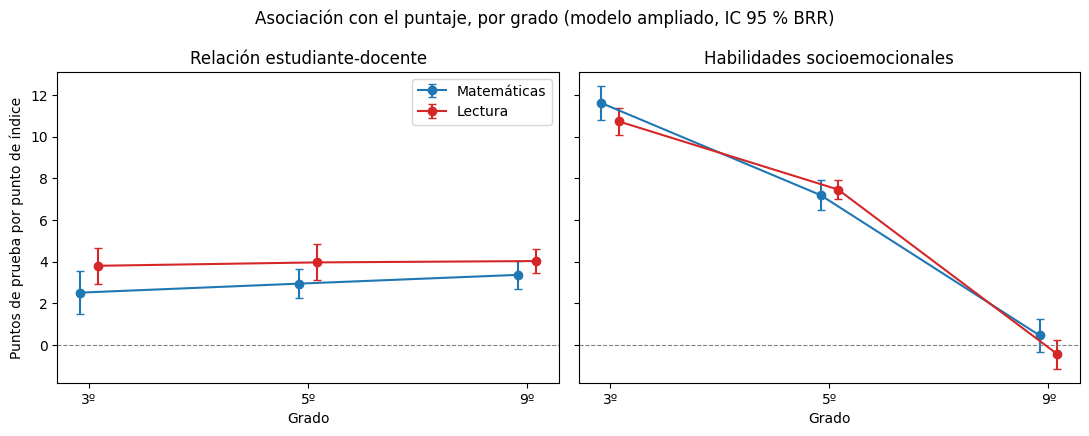

In [28]:
import matplotlib.pyplot as plt

nombres = {'doc_est': 'Relación estudiante-docente', 'socioe': 'Habilidades socioemocionales'}
colores = {'Matemáticas': '#1f77b4', 'Lectura': '#d62728'}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, var in zip(axes, ['doc_est', 'socioe']):
    for i, area in enumerate(['Matemáticas', 'Lectura']):
        s = tab_grado[(tab_grado['variable'] == var) & (tab_grado['area'] == area)]
        x = np.arange(3) + (i - 0.5) * 0.08
        ax.errorbar(x, s['coef'], yerr=[s['coef'] - s['IC95_inf'], s['IC95_sup'] - s['coef']],
                    fmt='o-', capsize=3, label=area, color=colores[area])
    ax.axhline(0, color='gray', lw=0.8, ls='--')
    ax.set_xticks(range(3)); ax.set_xticklabels(['3º', '5º', '9º'])
    ax.set_title(nombres[var]); ax.set_xlabel('Grado')
axes[0].set_ylabel('Puntos de prueba por punto de índice')
axes[0].legend()
fig.suptitle('Asociación con el puntaje, por grado (modelo ampliado, IC 95 % BRR)')
plt.tight_layout()
plt.savefig(DIR_SALIDA / 'fig_coef_por_grado.png', dpi=150)
plt.show()

In [29]:
print('Archivos generados en', DIR_SALIDA)
for f in sorted(DIR_SALIDA.glob('*')):
    print(' -', f.name)

Archivos generados en /content/drive/MyDrive/Colab Notebooks/saber-clima-aula/reports
 - coef_modelo4.csv
 - comparacion_tesis.csv
 - efectos_autorregulacion.csv
 - efectos_por_grado.csv
 - fig_coef_por_grado.png
 - validacion_python_stata.csv
